# Step 2: Power analysis

Plans the sample size for the primary metric, funded loans per user, using pre-experiment traffic only. A power analysis built on the test's own results would be circular, so this notebook generates four weeks of historical traffic in which every user sees the current experience, computes baseline statistics in SQL, and derives:

- the minimum detectable effect (MDE) at the planned sample size,
- the sample size and duration needed for a range of effect sizes,
- the expected gain from CUPED variance reduction using pre-period visits.

The results fill in the Power section of `docs/experiment_design.md`.

In [1]:
# Imports and paths.
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import src.simulate as sim

SQL = ROOT / "sql"
DB_PATH = ROOT / "data" / "marketplace.duckdb"
ALPHA, POWER = 0.05, 0.80

In [2]:
# Generate four weeks of historical traffic on the same marketplace (same partners as the
# experiment), with everyone in the current experience, and store it as hist_ tables.
_, partners, _ = sim.build_marketplace()
hist_users, hist_rng = sim.build_historical()
hist_impressions, hist_truth = sim.simulate_outcomes(hist_users, partners, hist_rng)

con = duckdb.connect(str(DB_PATH))
sim.load_to_duckdb(con, hist_users, partners, hist_impressions, hist_truth, prefix="hist_")
print(con.execute("SELECT COUNT(*) FROM hist_users").fetchone()[0], "historical users")

200000 historical users


In [3]:
# Baseline mean, variance and correlation with pre-period visits, computed in SQL.
base = con.execute((SQL / "05_baseline_stats.sql").read_text()).df().iloc[0]
print(base.round(4).to_string())

mean, var = base["funded_mean"], base["funded_var"]
users_per_day = base["users_per_day"]

users                 200000.0000
users_per_day           7142.8571
funded_mean                0.1549
funded_var                 0.1556
revenue_mean              28.4508
revenue_var             6195.0228
funded_prior_corr          0.0830
revenue_prior_corr         0.0783


In [4]:
# Minimum detectable effect at the planned size (28 days of traffic split 50/50), and the
# per-arm sample size needed for a range of relative lifts. For a two-sample difference in
# means: n per arm = 2 * var * (z_alpha/2 + z_power)^2 / delta^2.
z = stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(POWER)
n_planned = users_per_day * 28 / 2

mde_abs = z * np.sqrt(2 * var / n_planned)
print(f"Planned users per arm: {n_planned:,.0f}")
print(f"MDE: {mde_abs:.4f} funded loans per user, or {mde_abs / mean:.2%} relative to baseline {mean:.4f}")

lifts = np.array([0.01, 0.02, 0.03, 0.04, 0.05])
n_needed = 2 * var * z**2 / (lifts * mean) ** 2
plan = pd.DataFrame({
    "relative_lift": lifts,
    "users_per_arm": n_needed.round(),
    "days_needed": np.ceil(2 * n_needed / users_per_day),
})
# Round up to full weeks so every day of the week is represented equally.
plan["weeks_needed"] = np.ceil(plan["days_needed"] / 7).astype(int)
print(plan.to_string(index=False))

Planned users per arm: 100,000
MDE: 0.0049 funded loans per user, or 3.19% relative to baseline 0.1549
 relative_lift  users_per_arm  days_needed  weeks_needed
          0.01      1017580.0        285.0            41
          0.02       254395.0         72.0            11
          0.03       113064.0         32.0             5
          0.04        63599.0         18.0             3
          0.05        40703.0         12.0             2


In [5]:
# CUPED: adjusting for a pre-period covariate removes the share of variance it explains.
# Variance falls by a factor of (1 - rho^2), where rho is the correlation between the
# outcome and the covariate, so the required sample size falls by the same factor.
rho = base["funded_prior_corr"]
var_cuped = var * (1 - rho**2)
mde_cuped = z * np.sqrt(2 * var_cuped / n_planned)
print(f"Correlation of funded loans with prior visits: {rho:.3f}")
print(f"Variance reduction from CUPED: {rho**2:.1%}")
print(f"MDE with CUPED: {mde_cuped / mean:.2%} relative (vs {mde_abs / mean:.2%} without)")

Correlation of funded loans with prior visits: 0.083
Variance reduction from CUPED: 0.7%
MDE with CUPED: 3.18% relative (vs 3.19% without)


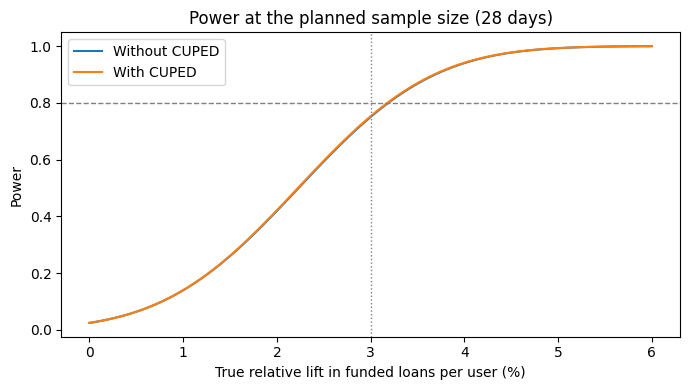

Power to detect a 3% lift: 75.0% without CUPED, 75.3% with


In [6]:
# Power curve at the planned sample size, with and without CUPED.
# The dashed line marks 80% power; the dotted line marks a 3% relative lift.
rel = np.linspace(0.0, 0.06, 121)
def power_at(rel_lift, variance):
    se = np.sqrt(2 * variance / n_planned)
    return stats.norm.cdf(rel_lift * mean / se - stats.norm.ppf(1 - ALPHA / 2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rel * 100, power_at(rel, var), label="Without CUPED")
ax.plot(rel * 100, power_at(rel, var_cuped), label="With CUPED")
ax.axhline(POWER, ls="--", c="gray", lw=1)
ax.axvline(3, ls=":", c="gray", lw=1)
ax.set_xlabel("True relative lift in funded loans per user (%)")
ax.set_ylabel("Power")
ax.set_title("Power at the planned sample size (28 days)")
ax.legend()
plt.tight_layout()
plt.savefig(ROOT / "docs" / "power_curve.png", dpi=150)
plt.show()

print(f"Power to detect a 3% lift: {power_at(0.03, var):.1%} without CUPED, {power_at(0.03, var_cuped):.1%} with")

In [7]:
# Close the database connection. DuckDB allows only one process to hold the file open,
# so leaving it open blocks the next notebook from connecting.
con.close()